# Zero-shot prediction from small tables

Can a pretrained tabular model predict categories and numbers from only 32 or 128 labeled examples better than ordinary fitted models? Small tables occur when a new process has collected only a few outcomes, so a wrong prediction can be expensive before there is enough data to tune a model.

We compare hosted TabPFN-3.5, without task-specific weight training or Thinking mode, with dummy, linear, random forest and histogram gradient boosting baselines. The data are 24 newly generated numeric tables: four mechanisms, classification and regression, and three seeds. Each has 128 context rows and 128 held-out rows; the 32-row context is a prefix of the same 128 rows.

**Headline result:** At 128 labeled rows, TabPFN scores 82.9% balanced accuracy (the mean fraction correct within each class) versus 71.7% for Random forest. Its regression error is 0.198 times the constant predictor's error versus 0.479 for Gradient boosting. The 48 hosted requests consumed 480,000 provider usage tokens; a USD charge was not returned. These are 24 synthetic tables and three seeds, not a general model ranking.

Here, zero-shot means no task-specific weight updates. The model still receives labeled examples as context. This experiment tests controlled numeric mechanisms, not accuracy on real business tables.

At 32 labeled rows, TabPFN scores 65.7% balanced accuracy, below Linear at 68.5%. The classification advantage appears at 128 rows in this run.

## Contents

1. [Setup and configuration](#1.-Setup-and-configuration)
2. [Fresh data and a look at the inputs](#2.-Fresh-data-and-a-look-at-the-inputs)
3. [Method and exact model requests](#3.-Method-and-exact-model-requests)
4. [Classification results](#4.-Classification-results)
5. [Regression results](#5.-Regression-results)
6. [Latency and usage](#6.-Latency-and-usage)
7. [Error analysis](#7.-Error-analysis)
8. [Limitations and reproduction](#8.-Limitations-and-reproduction)
9. [Future work and further reading](#9.-Future-work-and-further-reading)

```mermaid
flowchart LR
    A["Python generators<br/>4 mechanisms x 2 tasks x 3 seeds = 24 tables"] --> B["Freeze 256 rows per table<br/>128 context + 128 held-out"]
    B --> C["Nested context sizes<br/>32 and 128 labeled rows"]
    C --> D["Prior Labs REST API<br/>48 TabPFN predictions, 128 rows each"]
    C --> E["scikit-learn on local CPU<br/>192 baseline fits and predictions"]
    D --> F["Full request hashes<br/>48 cached model responses"]
    E --> G["Same held-out labels<br/>240 scored model runs"]
    F --> G
    G --> H["Paired comparisons, charts<br/>latency, usage and failure examples"]
```

Counts above describe the committed full run. `NB_SMOKE=1` selects two cached pilot requests without changing their data.

## 1. Setup and configuration

All helpers are defined here. Replay is the default and refuses a missing hosted response before opening a network connection. A live collection needs `NB_LIVE=1` and `PRIORLABS_API_KEY`. On Windows, the key may also be stored in the current user's environment registry. Credentials and signed upload URLs are never saved.

The main size controls are at the top. Eight estimators means eight internal model passes per prediction request, not eight separate HTTP predictions. The 600,000-token cap covers the full planned 480,000-token collection with room for a small recorded failure. Standard fitting prepares context; Thinking and weight fine-tuning are disabled.

In [1]:
import os, sys, json, hashlib, time, platform, importlib.metadata
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from IPython.display import display, Markdown
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                             HistGradientBoostingClassifier, HistGradientBoostingRegressor)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score, log_loss, brier_score_loss, mean_absolute_error
from threadpoolctl import threadpool_limits

MECHANISMS = ['linear', 'smooth', 'threshold', 'range_shift']
TASKS = ['classification', 'regression']
SEEDS = [101, 202, 303]
N_CONTEXT = [32, 128]
N_TEST = 128
N_FEATURES = 8
N_CONTEXT_POOL = 128
assert max(N_CONTEXT) <= N_CONTEXT_POOL and N_FEATURES >= 3
MODELS = ['TabPFN', 'Dummy', 'Linear', 'Random forest', 'Gradient boosting']
N_ESTIMATORS = 8
MAX_USAGE_TOKENS = 600_000
MAX_LIVE_PREDICTIONS = 48
N_BOOTSTRAP = 2000
MODEL_PATH = 'v3.5_default'
MODEL_VERSION = 'v3.5'
PROTOCOL = 'tabular-zero-shot-v1'
FIXTURE_DATE = '2026-10-19'
LIVE = os.environ.get('NB_LIVE') == '1'
SMOKE = os.environ.get('NB_SMOKE') == '1'
if SMOKE:
    MECHANISMS, SEEDS, N_CONTEXT = MECHANISMS[:1], SEEDS[:1], N_CONTEXT[:1]

DATA = Path('data')
CACHE = DATA / 'cache'
FIGURES = Path('figures')
for p in [DATA, CACHE, DATA / 'fixtures', FIGURES]:
    p.mkdir(parents=True, exist_ok=True)

# One style block for every chart in this notebook.
plt.rcParams.update({'figure.dpi': 130, 'savefig.dpi': 170, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .18, 'axes.titleweight': 'semibold',
                     'figure.facecolor': '#ffffff', 'axes.facecolor': '#ffffff'})
COLORS = dict(zip(MODELS, ['#16697a', '#8b949e', '#d17a22', '#7251a1', '#4c956c']))
LABELS = {'linear': 'Linear', 'smooth': 'Smooth nonlinear',
          'threshold': 'Threshold interaction', 'range_shift': 'Unseen input ranges'}
FEATURES = [f'x{i}' for i in range(N_FEATURES)]

def canonical(obj):
    return json.dumps(obj, sort_keys=True, separators=(',', ':'), allow_nan=False)

def digest(obj):
    return hashlib.sha256(canonical(obj).encode()).hexdigest()

def write_json(path, obj):
    path = Path(path)
    temp = path.with_suffix(path.suffix + '.tmp')
    temp.write_bytes((json.dumps(obj, indent=2, allow_nan=False) + '\n').encode('utf-8'))
    temp.replace(path)

def get_key():
    key = os.environ.get('PRIORLABS_API_KEY')
    if not key and os.name == 'nt':
        import winreg
        try:
            with winreg.OpenKey(winreg.HKEY_CURRENT_USER, 'Environment') as handle:
                key = winreg.QueryValueEx(handle, 'PRIORLABS_API_KEY')[0]
        except FileNotFoundError:
            pass
    if not key:
        raise RuntimeError('Live collection requires PRIORLABS_API_KEY.')
    return key

VERSIONS = {p: importlib.metadata.version(p) for p in
            ['numpy', 'pandas', 'matplotlib', 'requests', 'scikit-learn', 'nbconvert', 'nbformat', 'threadpoolctl']}
ENVIRONMENT = {'python': sys.version, 'platform': platform.platform(),
               'processor': platform.processor(), 'logical_cpus': os.cpu_count(), 'packages': VERSIONS}
if not (DATA / 'environment.json').exists():
    write_json(DATA / 'environment.json', ENVIRONMENT)
print(f'Live={LIVE}; smoke={SMOKE}; {len(MECHANISMS)*len(TASKS)*len(SEEDS)*len(N_CONTEXT)} hosted configurations')

Live=False; smoke=False; 48 hosted configurations


## 2. Fresh data and a look at the inputs

We generate numeric rows in code, then freeze the exact CSV bytes and their SHA-256 hashes. Every row was created for this experiment on 2026-10-19, after the [2026-09-15 TabPFN-3.5 release](https://priorlabs.ai/technical-reports). Prior Labs does not publish a training cutoff for the hosted Plus selector. No old benchmark rows are scored, no LLM writes records, and no date filtering is needed for these newly generated fixtures. The same simple function family may occur in pretraining; new rows prevent exact-example memory but do not test a new mathematical family.

Each table has eight numeric features; `x3` to `x7` are irrelevant noise features. Regression targets are the function value plus Gaussian noise with standard deviation 0.3. Classification targets are independent Bernoulli draws with probability `sigmoid(f(x))`, so some labels are unpredictable even with the correct function. The oracle value (the generator's known function value or event probability) stored beside each target is for scoring and error analysis only; it never enters a model request.

| Mechanism | Function f(x) | Context and test inputs |
|---|---|---|
| Linear | `2*x0 - x1 + 0.5*x2` | Features uniform on [-1, 1] |
| Smooth nonlinear | `2*sin(pi*x0) + x1**2 - 0.5*x2` | Same ranges in context and test |
| Threshold interaction | `2*sign(x0*x1) + 1.5*(x2>0) - 0.75` | Four quadrants and a step |
| Unseen input ranges | `2*x0 - x1 + 0.5*x2` | Context x0 in [-1, 1]; test x0 in [-3, -1.5] or [1.5, 3] |

The last mechanism has the same rule as Linear. Only the input range changes. The positive and negative test ranges keep both classification outcomes represented. Labels remain separate from feature uploads.

In [2]:
def signal(x, mechanism):
    if mechanism in ('linear', 'range_shift'):
        return 2*x[:, 0] - x[:, 1] + .5*x[:, 2]
    if mechanism == 'smooth':
        return 2*np.sin(np.pi*x[:, 0]) + x[:, 1]**2 - .5*x[:, 2]
    return 2*np.where(x[:, 0]*x[:, 1] >= 0, 1., -1.) + 1.5*(x[:, 2] > 0) - .75

def fixture(mechanism, seed, task):
    # Generate a fixed maximum context pool even in smoke mode.
    m = ['linear', 'smooth', 'threshold', 'range_shift'].index(mechanism)
    rng = np.random.default_rng(np.random.SeedSequence([seed, m, 1401]))
    x = rng.uniform(-1, 1, size=(N_CONTEXT_POOL + N_TEST, N_FEATURES))
    if mechanism == 'range_shift':
        x[N_CONTEXT_POOL:, 0] = rng.choice([-1, 1], N_TEST) * rng.uniform(1.5, 3., N_TEST)
    x = np.round(x, 6)
    f = signal(x, mechanism)
    label_rng = np.random.default_rng(np.random.SeedSequence([seed, m, int(task == 'regression'), 1402]))
    if task == 'classification':
        oracle = 1/(1+np.exp(-f))
        target = label_rng.binomial(1, oracle)
        assert set(target[:32]) == {0, 1} and set(target[N_CONTEXT_POOL:]) == {0, 1}
    else:
        oracle = f
        target = np.round(f + label_rng.normal(0, .3, len(f)), 6)
    frame = pd.DataFrame(x, columns=FEATURES)
    frame.insert(0, 'row_id', [f'{mechanism}-{seed}-{task}-{i:03}' for i in range(len(x))])
    frame['split'] = ['context']*N_CONTEXT_POOL + ['test']*N_TEST
    frame['target'] = target
    frame['oracle_value'] = np.round(oracle, 9)
    frame['created_date'] = FIXTURE_DATE
    return frame

FIXTURES = {}
manifest = []
for mechanism in MECHANISMS:
    for seed in SEEDS:
        for task in TASKS:
            frame = fixture(mechanism, seed, task)
            name = f'{mechanism}_{seed}_{task}'
            path = DATA / 'fixtures' / f'{name}.csv'
            content = frame.to_csv(index=False, lineterminator='\n').encode()
            if path.exists():
                assert path.read_bytes() == content, f'Frozen data changed: {path}'
            else:
                path.write_bytes(content)
            FIXTURES[name] = frame
            manifest.append({'dataset': name, 'mechanism': mechanism, 'seed': seed, 'task': task,
                             'created_date': FIXTURE_DATE, 'context_rows': N_CONTEXT_POOL, 'test_rows': N_TEST,
                             'features': N_FEATURES, 'sha256': hashlib.sha256(content).hexdigest(),
                             'path': str(path).replace('\\', '/'), 'source': 'synthetic Python generator',
                             'license': 'MIT, repository-authored code and generated fixtures'})
write_json(DATA / 'fixture_manifest.json', manifest)
MODEL_PROVENANCE = {
    'model': 'TabPFN-3.5 (hosted selector v3.5_default)', 'provider': 'Prior Labs hosted API', 'requested_selector': MODEL_PATH,
    'release_date': '2026-09-15', 'release_source': 'https://priorlabs.ai/technical-reports',
    'training_cutoff': 'not published for hosted Plus', 'source_checked': '2026-10-19',
    'access_terms': 'Prior Labs API terms; no model weights redistributed',
    'terms_source': 'https://priorlabs.ai/pricing',
    'date_filter': 'All records generated on 2026-10-19; no older public benchmark rows',
    'checkpoint_hash': 'not exposed by hosted API; response metadata retained per request',
    'method': 'labeled context at inference, 8 estimators, no Thinking or weight updates'}
write_json(DATA / 'model_provenance.json', MODEL_PROVENANCE)
display(pd.DataFrame(manifest).groupby(['mechanism', 'task'])[['context_rows', 'test_rows']].sum())
display(next(iter(FIXTURES.values())).head(6))
display(pd.DataFrame([MODEL_PROVENANCE])[['model', 'release_date', 'training_cutoff', 'date_filter']].T)

context_rows  test_rows
mechanism   task                                   
linear      classification           384        384
            regression               384        384
range_shift classification           384        384
            regression               384        384
smooth      classification           384        384
            regression               384        384
threshold   classification           384        384
            regression               384        384

,row_id,x0,x1,x2,x3,x4,x5,x6,x7,split,target,oracle_value,created_date
0,linear-101-classification-000,0.980006,0.163664,-0.258841,0.592739,0.702736,0.296501,-0.208334,-0.387270,context,1,0.841166,2026-10-19
1,linear-101-classification-001,-0.982710,-0.743253,-0.902634,0.835496,-0.041027,0.463320,-0.588310,-0.074705,context,0,0.157960,2026-10-19
2,linear-101-classification-002,-0.667308,0.770902,-0.603043,0.907056,0.543381,0.809586,0.253169,-0.763266,context,0,0.082637,2026-10-19
3,linear-101-classification-003,-0.469447,0.977392,0.331816,-0.955079,0.713084,-0.929198,-0.818787,-0.134506,context,0,0.148000,2026-10-19
4,linear-101-classification-004,-0.448448,-0.391466,0.239096,-0.942069,-0.386761,0.503165,-0.201976,-0.915347,context,0,0.404709,2026-10-19
5,linear-101-classification-005,0.642752,0.188969,0.306323,0.297884,0.863494,-0.272376,0.551433,0.425312,context,0,0.777247,2026-10-19


,0
model,TabPFN-3.5 (hosted selector v3.5_default)
release_date,2026-09-15
training_cutoff,not published for hosted Plus
date_filter,All records generated on 2026-10-19; no older ...


## 3. Method and exact model requests

The 32 labeled rows are a prefix of the 128-row context. Every method sees the same raw numeric features and labels, and predicts the same held-out rows. No model or hyperparameter is selected using test outcomes. Dummy returns the observed class proportions or the context mean. Linear is standardized logistic regression for classification and standardized ridge regression for numbers. Random forest uses 200 trees with at least two rows per leaf. Histogram gradient boosting uses 100 iterations, at most 15 leaves, at least five rows per leaf and L2 penalty 1. These are fixed baselines, not a tuning contest.

TabPFN receives a table rather than a natural-language prompt. The exact logical request includes the context features, context labels, unlabeled test features, selector, estimator count, random seed and output type. Its SHA-256 identifies the cache. Test labels and the generator's oracle values are excluded. We request class probabilities for classification and the conditional median for regression; the median targets mean absolute error. A plain fitted API context performs no task-specific weight updates.

```mermaid
sequenceDiagram
    participant N as Notebook
    participant C as Local response cache
    participant P as Prior Labs REST API
    participant S as Signed object storage
    N->>C: SHA-256 of full logical request
    alt Cached response exists
        C-->>N: Raw fit and prediction responses
    else NB_LIVE=1 and quota guard passes
        N->>P: Estimate tokens and check allowance
        P-->>N: Numeric usage estimate
        N->>P: Prepare context upload
        P-->>N: Temporary signed URLs
        N->>S: PUT context X and y CSVs
        N->>P: Fit standard TabPFN-3.5 context
        P-->>N: Fitted context ID (not Thinking)
        N->>P: Prepare test feature upload
        N->>S: PUT test X CSV, no labels
        N->>P: Predict 128 rows (wait for completion)
        P-->>N: Probabilities or numeric medians, metadata
        N->>C: Request, raw responses, timings, usage headers
    else Offline cache miss
        N-->>N: Stop before any network call
    end
```

Signed URLs are temporary credentials, so only safe upload IDs and the actual model responses are retained. There are no automatic billable retries. A stage journal makes a failed upload or fit resumable, and a failed prediction requires explicit inspection before retrying. The API protocol follows the [official REST guide](https://docs.priorlabs.ai/api/rest-quickstart); its schema snapshot and source hash are recorded during collection.

The server reports `tabpfn-v3.5-20260909.safetensors`, package 9.0.0, eight estimators and standard execution. Its effective-configuration metadata reports random seed 0 even though the requests contain seeds 101, 202 and 303. We retain both values in `data/model_runtime.json` and make no claim that the service honored the requested model seed. The three independent seeds define the synthetic data, which remain different in all cases. The response reports a CUDA device but no accelerator model.

In [3]:
BASE = 'https://api.priorlabs.ai'
_session = None
_live_count = 0

def api(method, route, body=None, timeout=180):
    global _session
    if not LIVE:
        raise RuntimeError('Network access is disabled in replay mode.')
    if _session is None:
        _session = requests.Session()
        _session.headers['Authorization'] = 'Bearer ' + get_key()
    response = _session.request(method, BASE + route, json=body, timeout=timeout)
    # Keep numeric metering headers only. Never retain Authorization or signed URLs.
    headers = {k: v for k, v in response.headers.items()
               if k.lower().startswith(('x-ratelimit', 'x-usage', 'x-token', 'x-credit'))}
    if not response.ok:
        # Error envelopes are diagnostic data. Strip the secret even if a server echoes it.
        detail = response.text[:1200].replace(get_key(), '[redacted]')
        raise RuntimeError(f'Prior Labs {route}: HTTP {response.status_code}: {detail}')
    return response.json(), headers

def safe_usage():
    raw, _ = api('POST', '/get_api_usage/')
    allowed = ['daily_tokens_used', 'daily_token_limit', 'monthly_tokens_used', 'monthly_token_limit',
               'daily_reset_time', 'monthly_reset_time']
    return {k: raw[k] for k in allowed if k in raw}

def preflight():
    path = DATA / 'provider_preflight.json'
    if not LIVE:
        if not path.exists():
            raise RuntimeError('No saved API preflight. Collect once with NB_LIVE=1.')
        return json.loads(path.read_text())
    settings, _ = api('GET', '/tabpfn/get_settings')
    usage = safe_usage()
    quotes = {}
    for n in N_CONTEXT:
        request = {'model_version': MODEL_VERSION, 'operation': 'predict', 'train_rows': n,
                   'test_rows': N_TEST, 'raw_columns': N_FEATURES, 'n_estimators': N_ESTIMATORS}
        quote, _ = api('POST', '/tabpfn/estimate_cost', request)
        quotes[str(n)] = {'request': request, 'response': quote}
    info = {'checked_at': datetime.now(timezone.utc).isoformat(), 'settings': settings,
            'usage_at_check': usage, 'quotes': quotes, 'currency_charge_usd': None,
            'currency_note': 'Provider reports computation tokens, not a USD charge or balance.'}
    if path.exists():
        old = json.loads(path.read_text())
        info['usage_before_collection'] = old.get('usage_before_collection', old['usage_at_check'])
        info['quotes'] = {**old['quotes'], **info['quotes']}
    else:
        info['usage_before_collection'] = usage
    write_json(path, info)
    schema_path = DATA / 'api_schema.json'
    if not schema_path.exists():
        raw = requests.get('https://docs.priorlabs.ai/api-reference/openapi.json', timeout=60)
        raw.raise_for_status()
        schema_path.write_text(json.dumps(raw.json(), indent=2) + '\n', encoding='utf-8')
    return info

PREFLIGHT = preflight()

def logical_request(frame, task, n, seed):
    context = frame.loc[frame.split == 'context'].iloc[:n]
    test = frame.loc[frame.split == 'test']
    return {'protocol': PROTOCOL, 'provider': 'Prior Labs', 'api_base': BASE,
            'task': task, 'columns': FEATURES, 'x_context': context[FEATURES].values.tolist(),
            'y_context': context.target.tolist(), 'x_test': test[FEATURES].values.tolist(),
            'fit_config': {'model_path': MODEL_PATH, 'n_estimators': N_ESTIMATORS,
                           'random_state': seed, 'fit_mode': 'fit_preprocessors'},
            'tabpfn_systems': ['preprocessing'],
            'predict_params': {'output_type': 'probas' if task == 'classification' else 'median'}}

def put_csv(info, frame):
    content = frame.to_csv(index=False, lineterminator='\n').encode()
    assert len(info['signed_urls']) == 1
    # Use a separate request so the provider Authorization header is never sent to storage.
    response = requests.put(info['signed_urls'][0], data=content,
                            headers=info['required_headers'], timeout=120)
    if not response.ok:
        raise RuntimeError(f'CSV storage upload failed with HTTP {response.status_code}')

def tabpfn_response(request):
    global _live_count
    key = digest(request)
    path = CACHE / f'tabpfn_{key}.json'
    if path.exists():
        saved = json.loads(path.read_text())
        assert saved['request'] == request and saved['request_sha256'] == key
        return saved
    if not LIVE:
        raise RuntimeError(f'Offline cache miss: {path}. No API call was made.')
    quote = PREFLIGHT['quotes'][str(len(request['x_context']))]['response']['estimated_cost']
    existing = list(CACHE.glob('tabpfn_*.json'))
    used = max(sum(json.loads(p.read_text())['estimated_tokens'] for p in existing),
               PREFLIGHT['usage_at_check']['monthly_tokens_used'] - PREFLIGHT['usage_before_collection']['monthly_tokens_used'])
    if used + quote > MAX_USAGE_TOKENS or _live_count >= MAX_LIVE_PREDICTIONS:
        raise RuntimeError('Notebook token or live-prediction cap reached.')
    # Account-wide remaining quota is checked once per execution; local budget is checked per call.
    check = PREFLIGHT['usage_at_check']
    remaining = min(check['daily_token_limit'] - check['daily_tokens_used'],
                    check['monthly_token_limit'] - check['monthly_tokens_used'])
    if quote * (1 + _live_count) > remaining:
        raise RuntimeError('Insufficient checked API allowance.')
    journal_path = CACHE / f'journal_{key}.json'
    journal = json.loads(journal_path.read_text()) if journal_path.exists() else {'request_sha256': key}
    if journal.get('prediction_started'):
        raise RuntimeError('An earlier prediction has uncertain status. Inspect its journal before any retry.')
    started = time.perf_counter()
    if 'fit_response' not in journal:
        prep, _ = api('POST', '/tabpfn/prepare_train_set_upload',
                      {'x_train_info': {'format': 'csv'}, 'y_train_info': {'format': 'csv'}})
        put_csv(prep['x_train_info'], pd.DataFrame(request['x_context'], columns=FEATURES))
        put_csv(prep['y_train_info'], pd.DataFrame({'target': request['y_context']}))
        fit_body = {'train_set_upload_id': prep['train_set_upload_id'],
                    'task_config': {'task': request['task'], 'tabpfn_config': request['fit_config']},
                    'tabpfn_systems': request['tabpfn_systems']}
        fitted, fit_headers = api('POST', '/tabpfn/fit', fit_body, timeout=300)
        journal.update(fit_request=fit_body, fit_response=fitted, fit_headers=fit_headers)
        write_json(journal_path, journal)
    fit_id = journal['fit_response']['fitted_train_set_id']
    if 'test_upload_id' not in journal:
        prep, _ = api('POST', '/tabpfn/prepare_test_set_upload',
                      {'fitted_train_set_id': fit_id, 'x_test_info': {'format': 'csv'}})
        put_csv(prep['x_test_info'], pd.DataFrame(request['x_test'], columns=FEATURES))
        journal['test_upload_id'] = prep['test_set_upload_id']
        write_json(journal_path, journal)
    predict_body = {'test_set_upload_id': journal['test_upload_id'], 'fitted_train_set_id': fit_id,
                    'task_config': {'task': request['task'], 'predict_params': request['predict_params']}}
    journal['prediction_started'] = True
    write_json(journal_path, journal)
    _live_count += 1
    result, response_headers = api('POST', '/tabpfn/predict', predict_body, timeout=300)
    # Small requests return inline JSON; do not persist signed response download URLs.
    if 'prediction' not in result:
        raise RuntimeError('Expected inline prediction; inspect protocol before proceeding.')
    saved = {'request_sha256': key, 'request': request,
             'collected_at': datetime.now(timezone.utc).isoformat(),
             'fit_request': journal['fit_request'], 'fit_response': journal['fit_response'],
             'predict_request': predict_body, 'raw_response': result,
             'usage_headers': response_headers, 'estimated_tokens': quote,
             'wall_seconds': time.perf_counter() - started, 'currency_charge_usd': None}
    write_json(path, saved)
    journal_path.unlink()
    return saved

BASELINE_CONFIG = {
    'Dummy': {'classification': 'prior', 'regression': 'mean'},
    'Linear': {'logistic_C': 1., 'ridge_alpha': 1., 'standardize': True},
    'Random forest': {'n_estimators': 200, 'min_samples_leaf': 2, 'max_features': 1.},
    'Gradient boosting': {'max_iter': 100, 'max_leaf_nodes': 15, 'min_samples_leaf': 5,
                          'l2_regularization': 1., 'learning_rate': .1, 'early_stopping': False}}

def baseline_response(request, method):
    logical = {'protocol': PROTOCOL, 'method': method, 'parameters': BASELINE_CONFIG[method],
               'task': request['task'], 'seed': request['fit_config']['random_state'],
               'columns': request['columns'], 'x_context': request['x_context'],
               'y_context': request['y_context'], 'x_test': request['x_test']}
    key = digest(logical)
    path = CACHE / f'baseline_{key}.json'
    if path.exists():
        result = json.loads(path.read_text())
        assert result['request'] == logical and result['request_sha256'] == key
        return result
    classification = request['task'] == 'classification'
    seed = logical['seed']
    if method == 'Dummy':
        model = DummyClassifier(strategy='prior') if classification else DummyRegressor(strategy='mean')
    elif method == 'Linear':
        estimator = LogisticRegression(C=1., max_iter=1000, random_state=seed) if classification else Ridge(alpha=1.)
        model = make_pipeline(StandardScaler(), estimator)
    elif method == 'Random forest':
        cls = RandomForestClassifier if classification else RandomForestRegressor
        model = cls(n_estimators=200, min_samples_leaf=2, max_features=1., random_state=seed, n_jobs=1)
    else:
        cls = HistGradientBoostingClassifier if classification else HistGradientBoostingRegressor
        model = cls(max_iter=100, max_leaf_nodes=15, min_samples_leaf=5,
                    l2_regularization=1., learning_rate=.1, early_stopping=False, random_state=seed)
    start = time.perf_counter()
    with threadpool_limits(limits=1):
        model.fit(np.array(request['x_context']), np.array(request['y_context']))
        x_test = np.array(request['x_test'])
        prediction = model.predict_proba(x_test).tolist() if classification else model.predict(x_test).tolist()
    saved = {'request_sha256': key, 'request': logical, 'prediction': prediction,
             'classes': model.classes_.tolist() if classification else None,
             'wall_seconds': time.perf_counter() - start, 'environment': ENVIRONMENT}
    write_json(path, saved)
    return saved

def parse_prediction(raw, task):
    prediction = np.asarray(raw['prediction'], dtype=float)
    assert np.isfinite(prediction).all()
    if task == 'classification':
        assert prediction.shape == (N_TEST, 2)
        assert np.allclose(prediction.sum(axis=1), 1., atol=1e-5)
        assert np.all((prediction >= 0) & (prediction <= 1))
        return prediction[:, 1]
    prediction = prediction.reshape(-1)
    assert prediction.shape == (N_TEST,)
    return prediction

records, prediction_rows, call_rows = [], [], []
for mechanism in MECHANISMS:
    for seed in SEEDS:
        for task in TASKS:
            dataset = f'{mechanism}_{seed}_{task}'
            frame = FIXTURES[dataset]
            test = frame.loc[frame.split == 'test']
            y_true = test.target.to_numpy()
            for n in N_CONTEXT:
                request = logical_request(frame, task, n, seed)
                dummy_mae = mean_absolute_error(y_true, np.repeat(np.mean(request['y_context']), N_TEST))
                for method in MODELS:
                    if method == 'TabPFN':
                        cached = tabpfn_response(request)
                        response = cached['raw_response']
                        assert response['metadata']['n_estimators'] == N_ESTIMATORS
                        assert response['metadata']['execution_mode'] == 'standard'
                        if task == 'classification':
                            assert response['metadata']['classes'] == [0, 1]
                        pred = parse_prediction(response, task)
                        call_rows.append({'dataset': dataset, 'task': task, 'mechanism': mechanism,
                                          'seed': seed, 'n_context': n, 'request_sha256': cached['request_sha256'],
                                          'estimated_tokens': cached['estimated_tokens'],
                                          'wall_seconds': cached['wall_seconds'],
                                          'metadata': response['metadata']})
                    else:
                        cached = baseline_response(request, method)
                        if task == 'classification':
                            assert cached['classes'] == [0., 1.] or cached['classes'] == [0, 1]
                        pred = parse_prediction(cached, task)
                    row = {'dataset': dataset, 'mechanism': mechanism, 'task': task, 'seed': seed,
                           'n_context': n, 'method': method, 'wall_seconds': cached['wall_seconds']}
                    if task == 'classification':
                        row.update(balanced_accuracy=balanced_accuracy_score(y_true, pred >= .5),
                                   log_loss=log_loss(y_true, np.column_stack([1-pred, pred]), labels=[0, 1]),
                                   brier=brier_score_loss(y_true, pred))
                    else:
                        mae = mean_absolute_error(y_true, pred)
                        row.update(mae=mae, relative_mae=mae/dummy_mae)
                    records.append(row)
                    for row_id, actual, oracle, value, x0 in zip(test.row_id, y_true, test.oracle_value, pred, test.x0):
                        prediction_rows.append({**{k: row[k] for k in ['dataset', 'mechanism', 'task', 'seed', 'n_context', 'method']},
                                                'row_id': row_id, 'actual': actual, 'oracle_value': oracle,
                                                'prediction': value, 'x0': x0})
                print(f'{dataset}, n={n}: cached or collected')
metrics = pd.DataFrame(records)
predictions = pd.DataFrame(prediction_rows)
calls = pd.DataFrame(call_rows)
metrics.to_csv(DATA / 'metrics.csv', index=False, lineterminator='\n')
predictions.to_csv(DATA / 'predictions.csv', index=False, lineterminator='\n')
calls.drop(columns='metadata').to_csv(DATA / 'calls.csv', index=False, lineterminator='\n')
if LIVE:
    write_json(DATA / 'usage_after.json', safe_usage())
assert len(calls) == len(MECHANISMS)*len(SEEDS)*len(TASKS)*len(N_CONTEXT)
print(f'Complete: {len(calls)} hosted predictions, {len(metrics)} scored runs, {len(predictions):,} row predictions.')

runtime_rows = []
for item in calls.itertuples():
    cache = json.loads((CACHE / f'tabpfn_{item.request_sha256}.json').read_text())
    meta = cache['raw_response']['metadata']
    effective = meta['tabpfn_config']
    runtime_rows.append({'request_sha256': item.request_sha256,
                         'requested_seed': cache['request']['fit_config']['random_state'],
                         'reported_seed': effective.get('random_state'),
                         'reported_checkpoint_path': effective.get('model_path'),
                         'server_package_version': meta.get('package_version'),
                         'reported_n_estimators': meta['n_estimators'],
                         'execution_mode': meta['execution_mode'],
                         'reported_device': effective.get('device')})
write_json(DATA / 'model_runtime.json', runtime_rows)
print('Server checkpoint:', sorted({r['reported_checkpoint_path'] for r in runtime_rows}))
print('Requested seeds:', sorted({r['requested_seed'] for r in runtime_rows}),
      'reported seeds:', sorted({r['reported_seed'] for r in runtime_rows}))


linear_101_classification, n=32: cached or collected


linear_101_classification, n=128: cached or collected
linear_101_regression, n=32: cached or collected
linear_101_regression, n=128: cached or collected
linear_202_classification, n=32: cached or collected
linear_202_classification, n=128: cached or collected
linear_202_regression, n=32: cached or collected
linear_202_regression, n=128: cached or collected
linear_303_classification, n=32: cached or collected
linear_303_classification, n=128: cached or collected


linear_303_regression, n=32: cached or collected
linear_303_regression, n=128: cached or collected


smooth_101_classification, n=32: cached or collected
smooth_101_classification, n=128: cached or collected
smooth_101_regression, n=32: cached or collected
smooth_101_regression, n=128: cached or collected
smooth_202_classification, n=32: cached or collected
smooth_202_classification, n=128: cached or collected
smooth_202_regression, n=32: cached or collected
smooth_202_regression, n=128: cached or collected


smooth_303_classification, n=32: cached or collected


...

threshold_202_regression, n=32: cached or collected
threshold_202_regression, n=128: cached or collected


threshold_303_classification, n=32: cached or collected
threshold_303_classification, n=128: cached or collected
threshold_303_regression, n=32: cached or collected
threshold_303_regression, n=128: cached or collected
range_shift_101_classification, n=32: cached or collected
range_shift_101_classification, n=128: cached or collected
range_shift_101_regression, n=32: cached or collected
range_shift_101_regression, n=128: cached or collected
range_shift_202_classification, n=32: cached or collected


range_shift_202_classification, n=128: cached or collected
range_shift_202_regression, n=32: cached or collected


range_shift_202_regression, n=128: cached or collected
range_shift_303_classification, n=32: cached or collected
range_shift_303_classification, n=128: cached or collected
range_shift_303_regression, n=32: cached or collected
range_shift_303_regression, n=128: cached or collected


Complete: 48 hosted predictions, 240 scored runs, 30,720 row predictions.
Server checkpoint: ['/app/tabpfn_models/tabpfn-v3.5-20260909.safetensors']
Requested seeds: [101, 202, 303] reported seeds: [0]


### One exact request, raw response and parsed result

The complete logical request is stored in the linked cache file. The preview below shows its shape and first row; it does not replace the saved full request. The raw JSON excerpt is shown beside the labels and parsed predictions so a reader can check class order and output parsing. The numerical values in this table are examples from the frozen test set, not extra model calls.

In [4]:
example_call = calls.iloc[0]
example_path = CACHE / f"tabpfn_{example_call.request_sha256}.json"
example = json.loads(example_path.read_text())
preview = {k: v for k, v in example['request'].items() if k not in ['x_context', 'y_context', 'x_test']}
preview.update(n_context=len(example['request']['x_context']), n_test=len(example['request']['x_test']),
               first_context=example['request']['x_context'][0], first_context_label=example['request']['y_context'][0],
               first_unlabeled_test=example['request']['x_test'][0])
display(Markdown(f'Full request and response: [{example_path.as_posix()}]({example_path.as_posix()})'))
print(json.dumps(preview, indent=2))
raw_preview = {**example['raw_response'], 'prediction': example['raw_response']['prediction'][:3]}
print('Raw response excerpt:', json.dumps(raw_preview, indent=2))
display(predictions.query('dataset == @example_call.dataset and n_context == @example_call.n_context and method == "TabPFN"')
        [['row_id', 'actual', 'oracle_value', 'prediction']].head(3))

Full request and response: [data/cache/tabpfn_b33e0335514f5e0e480fa23181c6ff284236133a0f3875114fda30791fe028f0.json](data/cache/tabpfn_b33e0335514f5e0e480fa23181c6ff284236133a0f3875114fda30791fe028f0.json)

{
  "protocol": "tabular-zero-shot-v1",
  "provider": "Prior Labs",
  "api_base": "https://api.priorlabs.ai",
  "task": "classification",
  "columns": [
    "x0",
    "x1",
    "x2",
    "x3",
    "x4",
    "x5",
    "x6",
    "x7"
  ],
  "fit_config": {
    "model_path": "v3.5_default",
    "n_estimators": 8,
    "random_state": 101,
    "fit_mode": "fit_preprocessors"
  },
  "tabpfn_systems": [
    "preprocessing"
  ],
  "predict_params": {
    "output_type": "probas"
  },
  "n_context": 32,
  "n_test": 128,
  "first_context": [
    0.980006,
    0.163664,
    -0.258841,
    0.592739,
    0.702736,
    0.296501,
    -0.208334,
    -0.38727
  ],
  "first_context_label": 1,
  "first_unlabeled_test": [
    -0.62643,
    -0.414987,
    0.094142,
    -0.370053,
    0.571945,
    0.963332,
    -0.087731,
    -0.12399
  ]
}
Raw response excerpt: {
  "prediction": [
    [
      0.5519789457321167,
      0.4480210542678833
    ],
    [
      0.6400948762893677,
      0.3599051535129547
    ],

,row_id,actual,oracle_value,prediction
0,linear-101-classification-128,0.0,0.311996,0.448021
1,linear-101-classification-129,0.0,0.062581,0.359905
2,linear-101-classification-130,1.0,0.723201,0.483091


## 4. Classification results

Balanced accuracy averages the fraction of correct predictions within each class, so positive and negative outcomes get equal weight. A constant classifier scores 0.5. Log loss penalizes probability assigned to the wrong label; smaller is better. Brier score is the mean squared difference between the predicted positive probability and the observed 0/1 label; smaller is better. We average each metric equally over the four mechanisms and three seeds, not by selecting the best test result.

The uncertainty bars below resample whole seed blocks, preserving the paired methods, mechanisms and context sizes. With only three seeds, these 95% bootstrap intervals describe these generators and are too small a study to rank models on real tables. The methods are fixed before the test labels are scored.

balanced_accuracy  log_loss   brier
n_context method                                                
32        Dummy                         0.5000    0.7048  0.2557
          Gradient boosting             0.6500    0.8574  0.2660
          Linear                        0.6847    0.6345  0.2122
          Random forest                 0.6694    0.6531  0.2207
          TabPFN                        0.6565    0.6382  0.2212
128       Dummy                         0.5000    0.6937  0.2503
          Gradient boosting             0.7126    0.6632  0.2121
          Linear                        0.7129    0.5252  0.1793
          Random forest                 0.7172    0.5589  0.1875
          TabPFN                        0.8291    0.4579  0.1424

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


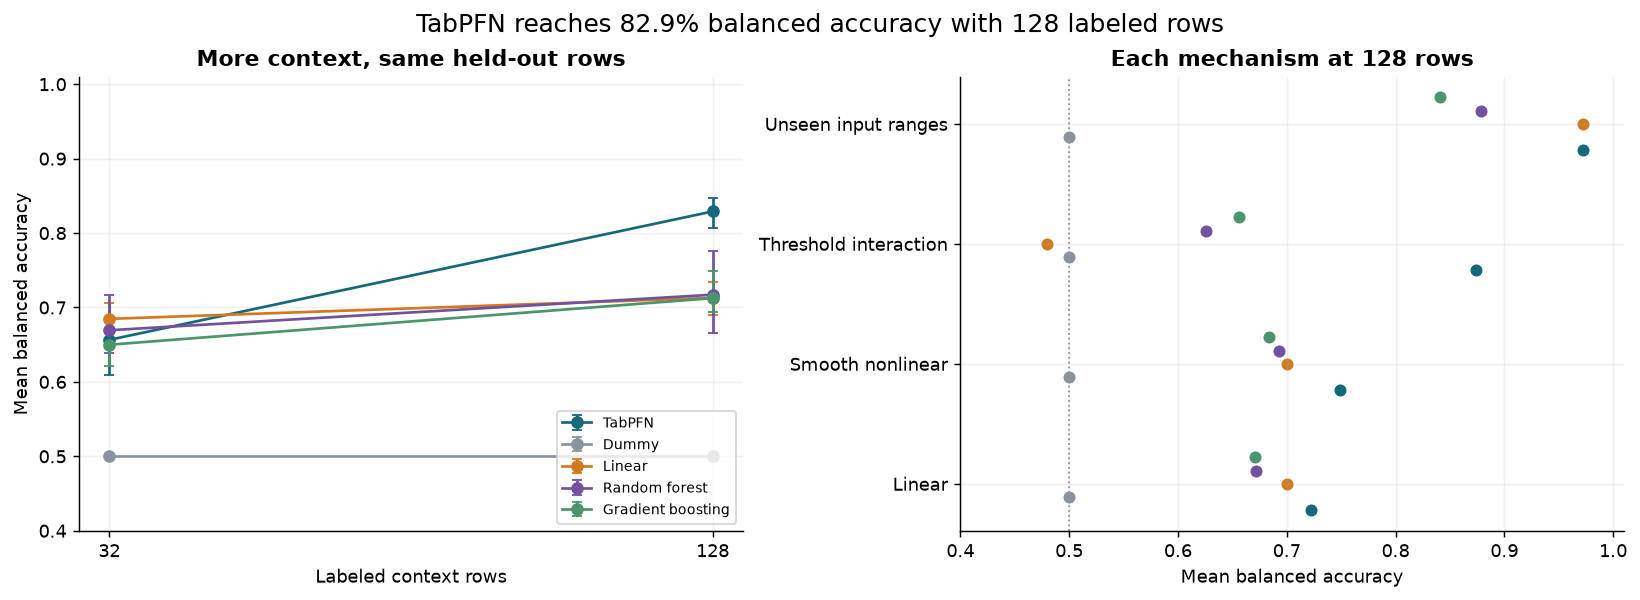

TabPFN scores 82.9% at 128 rows. The best mean baseline is Random forest at 71.7%, a paired difference of +11.2 percentage points. This baseline is identified after scoring; all four fixed baselines remain in the table.

In [5]:
def seed_interval(frame, metric):
    values = frame.groupby('seed')[metric].mean().to_numpy()
    if len(values) < 2:
        return float(values.mean()), float(values.mean()), float(values.mean())
    rng = np.random.default_rng(1403)
    draws = rng.choice(values, size=(N_BOOTSTRAP, len(values)), replace=True).mean(axis=1)
    return float(values.mean()), float(np.quantile(draws, .025)), float(np.quantile(draws, .975))

summary_rows = []
for (task, n, method), group in metrics.groupby(['task', 'n_context', 'method']):
    for metric in (['balanced_accuracy', 'log_loss', 'brier'] if task == 'classification' else ['mae', 'relative_mae']):
        mean, low, high = seed_interval(group, metric)
        summary_rows.append({'task': task, 'n_context': n, 'method': method, 'metric': metric,
                             'mean': mean, 'ci_low': low, 'ci_high': high})
summary = pd.DataFrame(summary_rows)
summary.to_csv(DATA / 'summary.csv', index=False, lineterminator='\n')
class_table = metrics.query('task == "classification"').groupby(['n_context', 'method'])[
    ['balanced_accuracy', 'log_loss', 'brier']].mean()
display(class_table.round(4))
max_n = max(N_CONTEXT)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5), layout='constrained')
for method in MODELS:
    group = summary.query('task == "classification" and metric == "balanced_accuracy" and method == @method').sort_values('n_context')
    axes[0].errorbar(group.n_context, group['mean'],
                     yerr=np.vstack([group['mean']-group.ci_low, group.ci_high-group['mean']]),
                     label=method, color=COLORS[method], marker='o', capsize=3)
    values = metrics.query('task == "classification" and n_context == @max_n and method == @method').groupby('mechanism').balanced_accuracy.mean().reindex(MECHANISMS)
    offset = (MODELS.index(method)-2)*.11
    axes[1].scatter(values, np.arange(len(MECHANISMS))+offset, color=COLORS[method], s=32)
axes[0].set(xlabel='Labeled context rows', ylabel='Mean balanced accuracy', xticks=N_CONTEXT,
            title='More context, same held-out rows', ylim=(.4, 1.01))
axes[1].set(xlabel='Mean balanced accuracy', yticks=range(len(MECHANISMS)),
            yticklabels=[LABELS[m] for m in MECHANISMS], title=f'Each mechanism at {max_n} rows', xlim=(.4, 1.01))
axes[1].axvline(.5, color=COLORS['Dummy'], ls=':', lw=1)
axes[0].legend(loc='lower right', fontsize=8)
tab_class = class_table.loc[(max_n, 'TabPFN'), 'balanced_accuracy']
fig.suptitle(f'TabPFN reaches {tab_class:.1%} balanced accuracy with {max_n} labeled rows', fontsize=14)
fig.savefig(FIGURES / 'classification.png', bbox_inches='tight')
plt.show()
best_class_baseline = class_table.loc[max_n].drop(index='TabPFN').balanced_accuracy.idxmax()
best_class_value = class_table.loc[(max_n, best_class_baseline), 'balanced_accuracy']
display(Markdown(f'TabPFN scores {tab_class:.1%} at {max_n} rows. The best mean baseline is {best_class_baseline} at {best_class_value:.1%}, a paired difference of {100*(tab_class-best_class_value):+.1f} percentage points. This baseline is identified after scoring; all four fixed baselines remain in the table.'))

## 5. Regression results

Mean absolute error (MAE) is the average absolute difference between a prediction and the observed numeric target. Relative MAE divides that error by Dummy's error on the same dataset and context size. A value of 0.4 means 60% less error than the constant context-mean predictor; 1 means the same error. We normalize per dataset before averaging so the larger targets outside the context range do not dominate the comparison.

The chart separates each mechanism. A low average can hide failure outside the observed input range. The uncertainty bars use the same seed-block bootstrap as classification.

mae  relative_mae
n_context method                                 
32        Dummy              2.2734        1.0000
          Gradient boosting  1.5132        0.6080
          Linear             0.9630        0.5340
          Random forest      1.5863        0.6517
          TabPFN             0.9203        0.4412
128       Dummy              2.2651        1.0000
          Gradient boosting  1.2701        0.4788
          Linear             0.8450        0.4849
          Random forest      1.3495        0.5167
          TabPFN             0.4344        0.1982

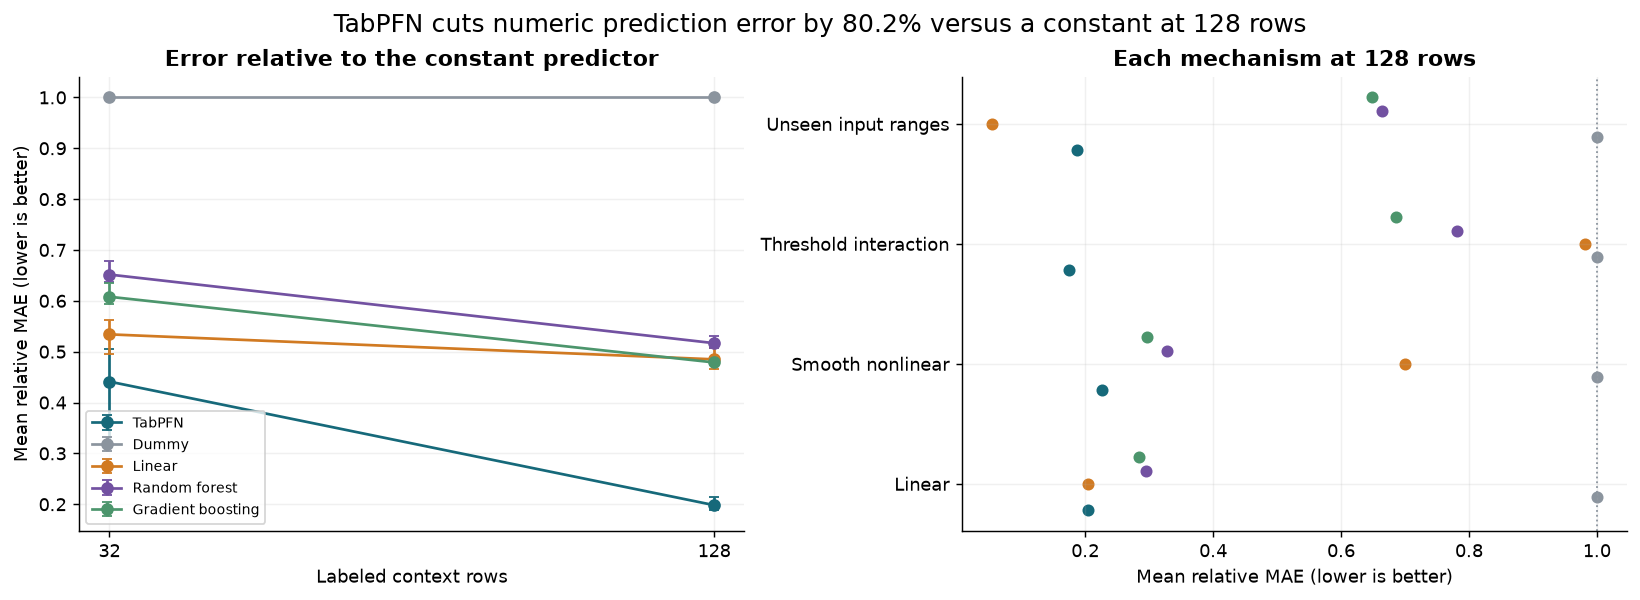

TabPFN has mean relative MAE 0.198 at 128 rows, compared with 0.479 for the best mean baseline, Gradient boosting. The average gives equal weight to each mechanism and seed.

,task,n_context,baseline,metric,tabpfn_minus_baseline,ci_low,ci_high
4,classification,128,Dummy,balanced_accuracy,0.3291,0.3068,0.3472
5,classification,128,Linear,balanced_accuracy,0.1162,0.0987,0.1324
6,classification,128,Random forest,balanced_accuracy,0.1119,0.0719,0.1676
7,classification,128,Gradient boosting,balanced_accuracy,0.1165,0.0988,0.1375
12,regression,128,Dummy,relative_mae,-0.8018,-0.8116,-0.7855
13,regression,128,Linear,relative_mae,-0.2868,-0.2931,-0.2749
14,regression,128,Random forest,relative_mae,-0.3186,-0.3427,-0.2921
15,regression,128,Gradient boosting,relative_mae,-0.2806,-0.2974,-0.2596


In [6]:
reg_table = metrics.query('task == "regression"').groupby(['n_context', 'method'])[['mae', 'relative_mae']].mean()
display(reg_table.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5), layout='constrained')
for method in MODELS:
    group = summary.query('task == "regression" and metric == "relative_mae" and method == @method').sort_values('n_context')
    axes[0].errorbar(group.n_context, group['mean'],
                     yerr=np.vstack([group['mean']-group.ci_low, group.ci_high-group['mean']]),
                     label=method, color=COLORS[method], marker='o', capsize=3)
    values = metrics.query('task == "regression" and n_context == @max_n and method == @method').groupby('mechanism').relative_mae.mean().reindex(MECHANISMS)
    offset = (MODELS.index(method)-2)*.11
    axes[1].scatter(values, np.arange(len(MECHANISMS))+offset, color=COLORS[method], s=32)
axes[0].set(xlabel='Labeled context rows', ylabel='Mean relative MAE (lower is better)', xticks=N_CONTEXT,
            title='Error relative to the constant predictor')
axes[1].set(xlabel='Mean relative MAE (lower is better)', yticks=range(len(MECHANISMS)),
            yticklabels=[LABELS[m] for m in MECHANISMS], title=f'Each mechanism at {max_n} rows')
axes[1].axvline(1., color=COLORS['Dummy'], ls=':', lw=1)
axes[0].legend(loc='best', fontsize=8)
tab_reg = reg_table.loc[(max_n, 'TabPFN'), 'relative_mae']
fig.suptitle(f'TabPFN cuts numeric prediction error by {1-tab_reg:.1%} versus a constant at {max_n} rows', fontsize=14)
fig.savefig(FIGURES / 'regression.png', bbox_inches='tight')
plt.show()
best_reg_baseline = reg_table.loc[max_n].drop(index='TabPFN').relative_mae.idxmin()
best_reg_value = reg_table.loc[(max_n, best_reg_baseline), 'relative_mae']
display(Markdown(f'TabPFN has mean relative MAE {tab_reg:.3f} at {max_n} rows, compared with {best_reg_value:.3f} for the best mean baseline, {best_reg_baseline}. The average gives equal weight to each mechanism and seed.'))

# Paired differences against every fixed baseline, never an oracle-picked per-table winner.
paired_rows = []
for task, metric in [('classification', 'balanced_accuracy'), ('regression', 'relative_mae')]:
    for n in N_CONTEXT:
        wide = metrics.query('task == @task and n_context == @n').pivot(index=['seed', 'mechanism'], columns='method', values=metric)
        for method in [m for m in MODELS if m != 'TabPFN']:
            difference = (wide.TabPFN - wide[method]).rename('delta').reset_index()
            mean, low, high = seed_interval(difference, 'delta')
            paired_rows.append({'task': task, 'n_context': n, 'baseline': method, 'metric': metric,
                                'tabpfn_minus_baseline': mean, 'ci_low': low, 'ci_high': high})
paired = pd.DataFrame(paired_rows)
paired.to_csv(DATA / 'paired_differences.csv', index=False, lineterminator='\n')
display(paired.query('n_context == @max_n').round(4))

## 6. Latency and usage

Hosted latency below includes context uploads, preprocessing, fit, test upload, waiting and prediction. Local baseline latency is CPU fitting plus prediction with one computational thread. These are different execution environments, so the chart measures the experience from this notebook, not model-only CPU versus GPU speed. Recorded cache times are replayed rather than timing file reads. The first hosted request may include startup cost.

The provider meters computation tokens rather than text tokens. Each planned request is quoted before collection. We retain the numeric account counters before and after the run and compare the difference with summed quotes. Account-wide differences can include another user's concurrent activity on the same key. Currency charges are not exposed by this endpoint, so a USD amount is reported as unknown rather than inferred from tokens.

,median,min,max
method,,,
TabPFN,8.112,6.019,82.474
Dummy,0.017,0.013,0.147
Linear,0.019,0.015,0.045
Random forest,0.199,0.138,0.308
Gradient boosting,0.063,0.035,1.692


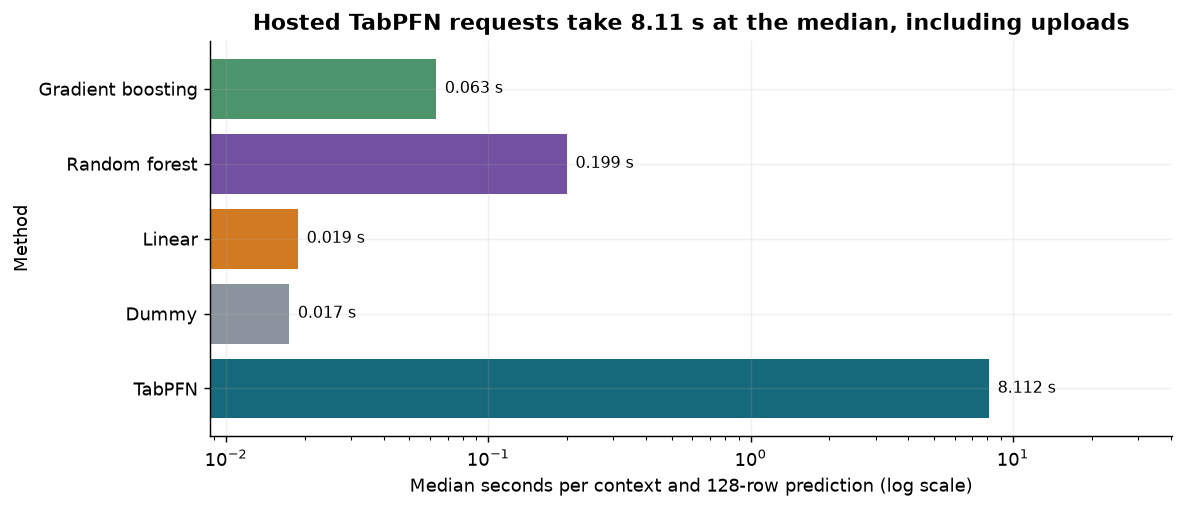

,hosted_requests,main_quote_tokens,account_token_delta,USD_charge,local_baseline_runs
0,48,480000,480000,not reported by provider,192


The 48 main prediction requests quote 480,000 tokens. The saved account counters increased by 480,000 tokens across collection. Median hosted wall time is 8.11 seconds; cached replay makes no hosted request.

In [7]:
latency = metrics.groupby('method').wall_seconds.agg(['median', 'min', 'max']).reindex(MODELS)
display(latency.round(3))
fig, ax = plt.subplots(figsize=(9, 3.8), layout='constrained')
bars = ax.barh(latency.index, latency['median'], color=[COLORS[m] for m in latency.index])
ax.set_xscale('log')
ax.set(xlabel='Median seconds per context and 128-row prediction (log scale)', ylabel='Method')
for bar, value in zip(bars, latency['median']):
    ax.text(value*1.08, bar.get_y()+bar.get_height()/2, f'{value:.3f} s', va='center', fontsize=9)
ax.set_xlim(max(latency['median'].min()/2, .0001), latency['median'].max()*5)
api_median = float(latency.loc['TabPFN', 'median'])
ax.set_title(f'Hosted TabPFN requests take {api_median:.2f} s at the median, including uploads')
fig.savefig(FIGURES / 'latency.png', bbox_inches='tight')
plt.show()
after = json.loads((DATA / 'usage_after.json').read_text())
before = PREFLIGHT['usage_before_collection']
token_delta = after['monthly_tokens_used'] - before['monthly_tokens_used']
quoted_tokens = int(calls.estimated_tokens.sum())
SPEND = {'main_prediction_requests': len(calls), 'scored_runs': len(metrics),
         'predictions_per_request': N_TEST, 'estimated_main_tokens': quoted_tokens,
         'account_token_delta': token_delta, 'currency_charge_usd': None,
         'currency_note': 'No USD charge is exposed by the API; no paid top-up was initiated.',
         'usage_before': before, 'usage_after': after, 'hardware': 'Hosted hardware not exposed; local CPU in environment.json'}
write_json(DATA / 'spend.json', SPEND)
display(pd.DataFrame([{'hosted_requests': len(calls), 'main_quote_tokens': quoted_tokens,
                       'account_token_delta': token_delta, 'USD_charge': 'not reported by provider',
                       'local_baseline_runs': len(metrics)-len(calls)}]))
display(Markdown(f'The {len(calls)} main prediction requests quote {quoted_tokens:,} tokens. The saved account counters increased by {token_delta:,} tokens across collection. Median hosted wall time is {api_median:.2f} seconds; cached replay makes no hosted request.'))

## 7. Error analysis

We inspect the dataset where TabPFN loses most MAE to Linear among the shifted-range regression tables. This is selected after scoring as a failure example, not as an independent confirmatory test. The left panel shows actual numeric outcomes and predictions. The right panel places signed prediction error against `x0`; the shaded center is the range that appeared in the labeled context. A model that flattens outside that range can have reasonable interpolation accuracy and poor extrapolation.

Classification failures below include the known event probability as well as the observed label. A confident wrong answer near a true probability of 0.5 may be label noise; a prediction far from the true probability is a model error. The reported probability is never used as a training feature.

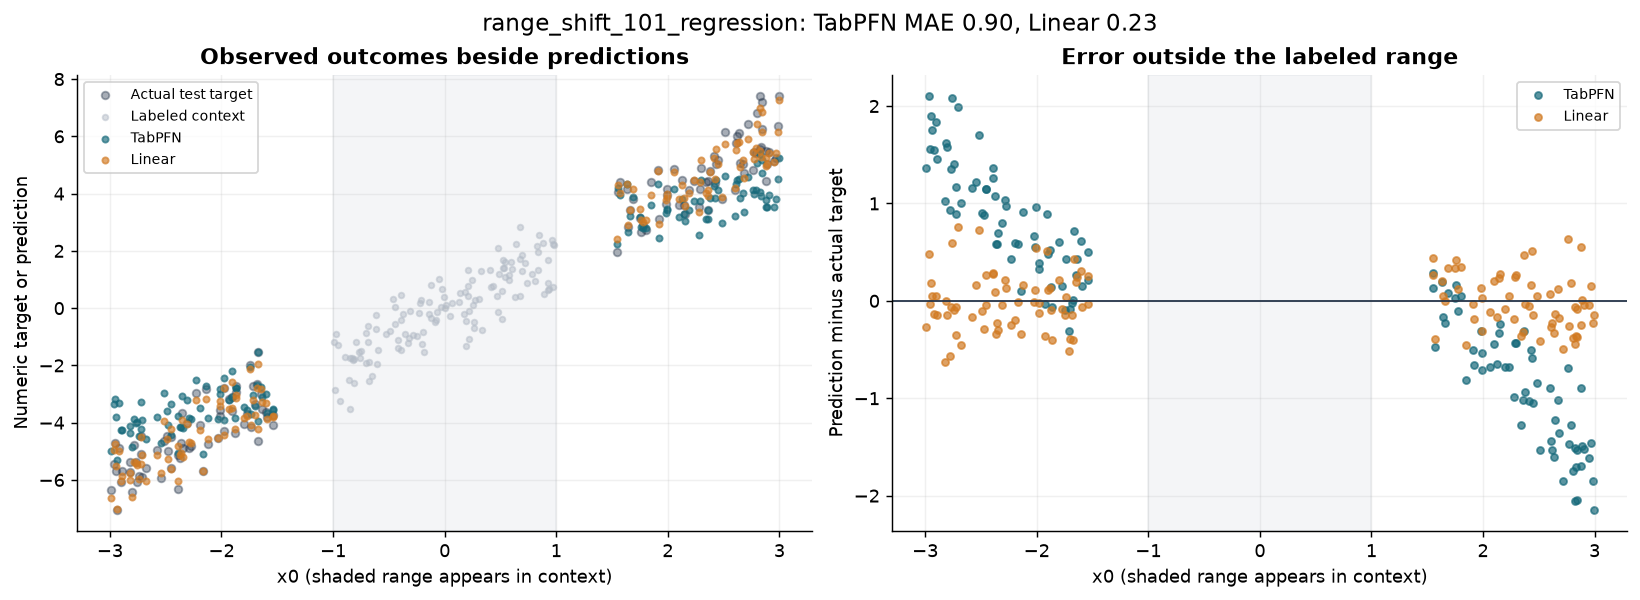

method,row_id,actual,x0,Linear,TabPFN,TabPFN_absolute_error
20,range_shift-101-regression-148,7.4063,2.9929,7.2593,5.2585,2.1477
11,range_shift-101-regression-139,-5.4455,-2.9678,-4.9638,-3.3392,2.1064
25,range_shift-101-regression-153,-6.0660,-2.7602,-5.4764,-3.9874,2.0786
118,range_shift-101-regression-246,7.4198,2.8286,6.9727,5.3681,2.0517
68,range_shift-101-regression-196,7.2133,2.8410,6.8428,5.1718,2.0414
53,range_shift-101-regression-181,-5.8919,-2.7097,-5.1337,-3.9063,1.9856


,row_id,mechanism,actual,oracle_value,prediction,confidence
16096,threshold-101-classification-224,threshold,0.0,0.9399,0.9796,0.9796
16086,threshold-101-classification-214,threshold,0.0,0.9399,0.9779,0.9779
16001,threshold-101-classification-129,threshold,0.0,0.9399,0.9769,0.9769
16002,threshold-101-classification-130,threshold,0.0,0.9399,0.9487,0.9487
16090,threshold-101-classification-218,threshold,0.0,0.7773,0.9399,0.9399
18614,threshold-202-classification-182,threshold,0.0,0.7773,0.9362,0.9362


In the selected failure example, TabPFN MAE is 0.899 and Linear MAE is 0.234. These rows use inputs outside the labeled range; the rule itself is unchanged.

In [8]:
eligible = metrics.query('task == "regression" and n_context == @max_n')
if 'range_shift' in MECHANISMS:
    eligible = eligible.query('mechanism == "range_shift"')
comparison = eligible.pivot(index='dataset', columns='method', values='mae')
failure_dataset = (comparison.TabPFN-comparison.Linear).idxmax()
error = predictions.query('dataset == @failure_dataset and n_context == @max_n and method in ["TabPFN", "Linear"]')
frame = FIXTURES[failure_dataset]
context = frame.query('split == "context"').iloc[:max_n]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5), layout='constrained')
actual = frame.query('split == "test"')
axes[0].scatter(actual.x0, actual.target, color='#253449', alpha=.4, s=18, label='Actual test target')
axes[0].scatter(context.x0, context.target, color='#b4bcc7', s=10, alpha=.5, label='Labeled context')
for method in ['TabPFN', 'Linear']:
    points = error.query('method == @method')
    axes[0].scatter(points.x0, points.prediction, color=COLORS[method], s=12, alpha=.65, label=method)
    axes[1].scatter(points.x0, points.prediction-points.actual, color=COLORS[method], s=15, alpha=.7, label=method)
axes[1].axhline(0, color='#253449', lw=1)
for ax in axes:
    ax.axvspan(-1, 1, color='#b4bcc7', alpha=.14)
    ax.set_xlabel('x0 (shaded range appears in context)')
    ax.legend(fontsize=8)
axes[0].set(ylabel='Numeric target or prediction', title='Observed outcomes beside predictions')
axes[1].set(ylabel='Prediction minus actual target', title='Error outside the labeled range')
failure_mae = comparison.loc[failure_dataset]
fig.suptitle(f'{failure_dataset}: TabPFN MAE {failure_mae.TabPFN:.2f}, Linear {failure_mae.Linear:.2f}', fontsize=13)
fig.savefig(FIGURES / 'error_example.png', bbox_inches='tight')
plt.show()
wide_error = error.pivot(index=['row_id', 'actual', 'x0'], columns='method', values='prediction').reset_index()
wide_error['TabPFN_absolute_error'] = abs(wide_error.TabPFN-wide_error.actual)
display(wide_error.nlargest(6, 'TabPFN_absolute_error').round(4))
class_errors = predictions.query('task == "classification" and n_context == @max_n and method == "TabPFN"').copy()
class_errors['wrong'] = (class_errors.prediction >= .5).astype(int) != class_errors.actual
class_errors['confidence'] = np.maximum(class_errors.prediction, 1-class_errors.prediction)
display(class_errors.query('wrong').nlargest(6, 'confidence')[
    ['row_id', 'mechanism', 'actual', 'oracle_value', 'prediction', 'confidence']].round(4))
display(Markdown(f'In the selected failure example, TabPFN MAE is {failure_mae.TabPFN:.3f} and Linear MAE is {failure_mae.Linear:.3f}. These rows use inputs outside the labeled range; the rule itself is unchanged.'))

RESULT = {'n_context': max_n, 'classification_balanced_accuracy': float(tab_class),
          'best_class_baseline': best_class_baseline, 'best_class_baseline_score': float(best_class_value),
          'regression_relative_mae': float(tab_reg), 'best_reg_baseline': best_reg_baseline,
          'best_reg_baseline_relative_mae': float(best_reg_value), 'hosted_median_seconds': api_median,
          'failure_dataset': failure_dataset, 'failure_tabpfn_mae': float(failure_mae.TabPFN),
          'failure_linear_mae': float(failure_mae.Linear), 'spend': SPEND}
write_json(DATA / 'headline.json', RESULT)

## 8. Limitations and reproduction

### Limits

There are only four numeric mechanisms and three seeds. The reported intervals resample seeds with mechanisms held fixed; they do not describe new mechanisms or real business populations. The fixtures have no categorical strings, missing values, text, grouped entities or temporal leakage. They cannot test the Plus model's text-processing claims. Classification includes irreducible random label noise. Its oracle probabilities are known, but they are not used to tune methods.

The baselines use fixed hyperparameters. No tuning budget is matched, and the best mean baseline is identified after evaluation. Eight TabPFN passes are not equal compute to one local baseline fit. The provider exposes a version selector, dated checkpoint filename and CUDA device, but no immutable checkpoint hash or accelerator model, so cached responses are the reproducibility boundary. Latency includes network and storage work and is not a CPU/GPU model-speed comparison. No other hosted foundation model is evaluated.

### Reproduce

From this notebook's directory, install `data/requirements-lock.txt` into a Python 3.13 environment, then execute:

```bash
python -m nbconvert --to notebook --execute --inplace 14_tabular_zero_shot.ipynb
```

All 48 model responses are read from `data/cache/`. No key or network access is needed. The fixed fixture bytes are checked before scoring. Baseline responses also replay recorded predictions and timings. `NB_SMOKE=1` selects two configurations already included in the full cache.

For a new collection, make a copy of the notebook folder, remove its response caches, provider preflight, usage, and stage journals, set `PRIORLABS_API_KEY` and `NB_LIVE=1`, and run top to bottom. Increase the size knobs and token cap together only after checking an updated cost quote. For more than 128 context rows, increase `N_CONTEXT_POOL` and generate new fixtures in the copied folder. A provider error stops collection; it does not silently replace the foundation model with a baseline. Inspect any journal with an uncertain prediction before retrying, because an interrupted request may already have consumed tokens. For new generated data, remove the copied `data/fixtures/` and `fixture_manifest.json`, update `FIXTURE_DATE`, and regenerate them in the copied folder. Change `PROTOCOL` whenever the logical request or interpretation changes. Do not edit frozen fixture files to alter an existing run.

`fixture_manifest.json` records input hashes; `model_provenance.json` records release and access sources; `environment.json` records the collecting machine; `api_schema.json` records the documented API; each cache stores its exact request, raw response and measured wall time. `metrics.csv`, `predictions.csv`, `summary.csv`, `paired_differences.csv`, `calls.csv` and `spend.json` are derived outputs.

## 9. Future work and further reading

Links checked on 2026-10-19. The next experiments should test the boundaries exposed by this small numeric study.

### Future work

- Repeat all four mechanisms with 30 seeds and 512 or 2,048 context rows. Measure paired changes in balanced accuracy and relative MAE; the current classification gap is +11.2 percentage points over only three seeds.
- Add newly collected real numeric and categorical tables with outcomes created after each model's release. Measure whether the ordering seen on these four synthetic mechanisms survives missing values, strings and genuine label noise.
- Compare TabPFN-3.5 with TabICLv2 and Google TabFM on exactly these frozen rows, at the same estimator or latency budget where possible. Measure per-mechanism differences; the current study contains only one foundation-model family.
- Add a declared linear-trend feature or a linear residual model to the shifted-range regression task, without looking at test labels. Measure extrapolation MAE; the selected failure has TabPFN MAE 0.899 versus Linear 0.234 outside the labeled range.
- Fit probability calibration only on a separate validation split and test more extreme class imbalance. Measure held-out log loss and Brier score; the current confident classification errors and random labels motivate separating probability error from unavoidable outcome noise.

### Further reading

- [Why do tree-based models still outperform deep learning on tabular data?](https://arxiv.org/abs/2207.08815) (Grinsztajn et al., 2022). The paper motivates explicit tests of irrelevant features and irregular response functions alongside tree baselines.
- [On Calibration of Modern Neural Networks](https://arxiv.org/abs/1706.04599) (Guo et al., 2017). This explains why a predicted probability needs evaluation beyond the fraction of correct labels.
- [Cross-validation failure: small sample sizes lead to large error bars](https://arxiv.org/abs/1706.07581) (Varoquaux, 2018). This motivates treating the three-seed intervals as a limited description of these fixtures.
- [TabICLv2: A better, faster, scalable, and open tabular foundation model](https://arxiv.org/abs/2602.11139) (Qu et al., 2026). This gives an open model for a follow-up comparison on the same classification and regression rows.